# Step 3: econometric model on the feasible series

Scope follows `01_data_feasibility.md`. The model estimates:

1. Singapore monthly trend growth of HS 2202 imports (world) and of the flavoured lane 2202.10, with month dummies and Newey-West (HAC) standard errors.
2. Singapore import-share trends: Thailand's share of HS 2202, and Malaysia's and Thailand's shares of the flavoured lane.
3. A structural-shift check for 2025 onward.
4. A 36-month forecast of the HS 2202 total with 80 percent prediction intervals.
5. A descriptive Korea trend on seven annual points, reported with its wide interval only.

Price response is not estimated. There is no price series (see step 1).

Inputs: `data/singstat_hs2202_monthly_imports_2023_2026.csv` (SingStat T010001, validated) and `../korea-chart/korea_hs2202_imports_2019_2025.csv` (UN Comtrade preview, provisional for 2025).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

HERE = Path.cwd()
SG_PATH = HERE / "data" / "singstat_hs2202_monthly_imports_2023_2026.csv"
KR_PATH = HERE.parent / "korea-chart" / "korea_hs2202_imports_2019_2025.csv"
RESULTS = HERE / "data"
RESULTS.mkdir(exist_ok=True)

df = pd.read_csv(SG_PATH)
df["date"] = pd.to_datetime(df["year"].astype(str) + "-" + df["month"], format="%Y-%b")
df = df.set_index("date").sort_index()
df["t"] = np.arange(len(df))
cols = ["world_2202", "world_220210", "thailand_2202", "thailand_220210", "malaysia_220210"]
assert df[cols].notna().all().all(), "missing monthly values"
print(len(df), "months from", df.index[0].strftime("%Y-%m"), "to", df.index[-1].strftime("%Y-%m"))

45 months from 2023-01 to 2026-09


In [2]:
def design(frame):
    months = pd.get_dummies(frame.index.month, prefix="m", drop_first=True, dtype=float)
    months.index = frame.index
    X = pd.concat([frame[["t"]], months], axis=1)
    return sm.add_constant(X)

X = design(df)
print(list(X.columns))

['const', 't', 'm_2', 'm_3', 'm_4', 'm_5', 'm_6', 'm_7', 'm_8', 'm_9', 'm_10', 'm_11', 'm_12']


## 1. Trend growth of Singapore HS 2202 imports (log-linear, month dummies, HAC)

In [3]:
def fit_log_trend(y_col):
    y = np.log(df[y_col])
    res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    b, se = res.params["t"], res.bse["t"]
    annual = lambda x: np.exp(12 * x) - 1
    row = {
        "series": y_col,
        "annual_growth": annual(b),
        "ci95_low": annual(b - 1.96 * se),
        "ci95_high": annual(b + 1.96 * se),
        "r2": res.rsquared,
        "resid_sd_log": float(np.sqrt(res.scale)),
        "n_months": int(res.nobs),
    }
    return res, row

resA, rowA = fit_log_trend("world_2202")
resB, rowB = fit_log_trend("world_220210")
trend = pd.DataFrame([rowA, rowB])
trend.round(4)

,series,annual_growth,ci95_low,ci95_high,r2,resid_sd_log,n_months
0,world_2202,0.0086,-0.0079,0.0254,0.6738,0.0737,45
1,world_220210,0.0002,-0.0175,0.0182,0.7388,0.0740,45


## 2. Import-share trends (logit of share, HAC)

In [4]:
def fit_share_trend(num, den, label):
    p = (df[num] / df[den]).clip(1e-4, 1 - 1e-4)
    y = np.log(p / (1 - p))
    res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    p_mean = p.mean()
    pp_per_year = p_mean * (1 - p_mean) * res.params["t"] * 12 * 100
    return {
        "share": label,
        "mean_share_pct": p_mean * 100,
        "pp_change_per_year_approx": pp_per_year,
        "t_stat": res.tvalues["t"],
        "p_value": res.pvalues["t"],
    }

shares = pd.DataFrame([
    fit_share_trend("thailand_2202", "world_2202", "Thailand share of HS 2202"),
    fit_share_trend("thailand_220210", "world_220210", "Thailand share of flavoured lane 2202.10"),
    fit_share_trend("malaysia_220210", "world_220210", "Malaysia share of flavoured lane 2202.10"),
])
shares.round(4)

,share,mean_share_pct,pp_change_per_year_approx,t_stat,p_value
0,Thailand share of HS 2202,9.6903,0.6716,4.9922,0.0
1,Thailand share of flavoured lane 2202.10,1.8009,0.5260,8.7431,0.0
2,Malaysia share of flavoured lane 2202.10,73.6890,-2.1214,-7.8848,0.0


## 3. Structural-shift check for 2025 onward

In [5]:
X_break = X.copy()
X_break["post2025"] = (df.index >= "2025-01-01").astype(float)
resBrk = sm.OLS(np.log(df["world_2202"]), X_break).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
brk = {"level_shift_log_points": resBrk.params["post2025"], "p_value": resBrk.pvalues["post2025"]}
print({k: round(v, 4) for k, v in brk.items()})

{'level_shift_log_points': np.float64(0.0105), 'p_value': np.float64(0.5825)}


## 4. Forecast, 36 months, with 80 percent prediction intervals

In [6]:
future_idx = pd.date_range(df.index[-1] + pd.offsets.MonthBegin(1), periods=36, freq="MS")
Xf = pd.DataFrame(0.0, index=future_idx, columns=X.columns)
Xf["const"] = 1.0
Xf["t"] = np.arange(len(df), len(df) + 36)
for idx in future_idx:
    if idx.month > 1:
        Xf.loc[idx, f"m_{idx.month}"] = 1.0

pred = resA.get_prediction(Xf).summary_frame(alpha=0.2)
fc = pd.DataFrame({
    "mean_sgd_k": np.exp(pred["mean"]),
    "lo80_sgd_k": np.exp(pred["obs_ci_lower"]),
    "hi80_sgd_k": np.exp(pred["obs_ci_upper"]),
}, index=future_idx)
annual_fc = fc.groupby(fc.index.year).sum()
annual_fc.round(0)

,mean_sgd_k,lo80_sgd_k,hi80_sgd_k
2026,121358.0,109511.0,134489.0
2027,454187.0,408167.0,505406.0
2028,458103.0,410173.0,511647.0
2029,337529.0,300949.0,378567.0


## 5. Korea descriptive trend (seven annual points, provisional 2025)

In [7]:
kr = pd.read_csv(KR_PATH)
kr_rows = []
for col in ["all_origins_usd", "thailand_usd"]:
    Xk = sm.add_constant((kr["year"] - 2019).astype(float))
    rk = sm.OLS(np.log(kr[col]), Xk).fit()
    b, se = rk.params.iloc[1], rk.bse.iloc[1]
    kr_rows.append({
        "series": "Korea HS 2202 imports, " + col.replace("_usd", ""),
        "annual_growth": np.exp(b) - 1,
        "ci95_low": np.exp(b - 1.96 * se) - 1,
        "ci95_high": np.exp(b + 1.96 * se) - 1,
        "r2": rk.rsquared,
        "n_years": int(rk.nobs),
    })
korea_trend = pd.DataFrame(kr_rows)
korea_trend.round(4)

,series,annual_growth,ci95_low,ci95_high,r2,n_years
0,"Korea HS 2202 imports, all_origins",0.0798,0.0378,0.1234,0.7423,7
1,"Korea HS 2202 imports, thailand",0.0874,0.0193,0.1600,0.5634,7


## 6. Save results and draw the Singapore fit

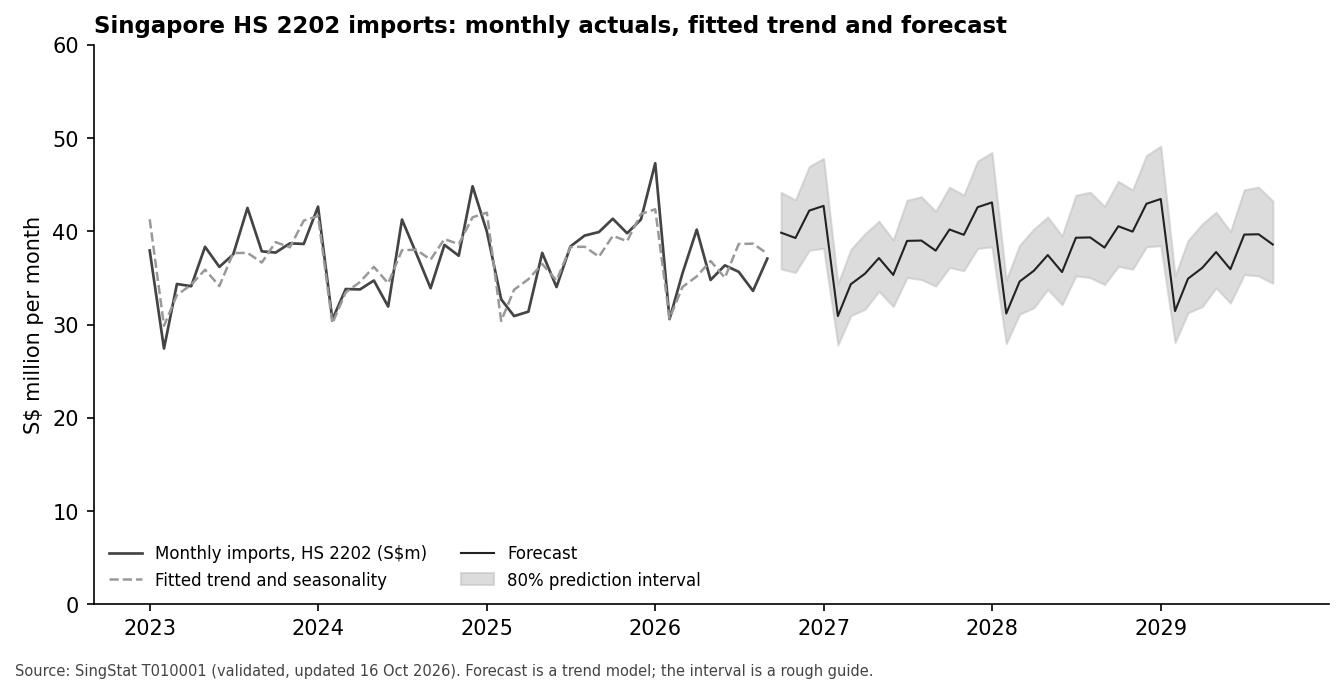

saved results and figure


In [8]:
trend_out = pd.concat([trend, korea_trend], ignore_index=True)
trend_out.to_csv(RESULTS / "econ_trend_results.csv", index=False)
shares.to_csv(RESULTS / "econ_share_results.csv", index=False)
annual_fc.to_csv(RESULTS / "econ_forecast_annual_sgd_k.csv")

fig, ax = plt.subplots(figsize=(9, 4.6), dpi=150, facecolor="white")
ax.plot(df.index, df["world_2202"] / 1000, color="#444444", lw=1.3, label="Monthly imports, HS 2202 (S$m)")
ax.plot(df.index, np.exp(resA.fittedvalues) / 1000, color="#999999", lw=1.2, ls="--", label="Fitted trend and seasonality")
ax.plot(fc.index, fc["mean_sgd_k"] / 1000, color="#222222", lw=1.0, label="Forecast")
ax.fill_between(fc.index, fc["lo80_sgd_k"] / 1000, fc["hi80_sgd_k"] / 1000, color="#bbbbbb", alpha=0.5, label="80% prediction interval")
ax.set_ylabel("S$ million per month")
ax.set_ylim(0, 60)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left", ncol=2)
ax.set_title("Singapore HS 2202 imports: monthly actuals, fitted trend and forecast", loc="left", fontsize=11, fontweight="bold")
fig.text(0.01, 0.01, "Source: SingStat T010001 (validated, updated 16 Oct 2026). Forecast is a trend model; the interval is a rough guide.", fontsize=7, color="#444444")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(HERE / "03_econometric_fit.png", dpi=150, facecolor="white")
plt.show()
print("saved results and figure")